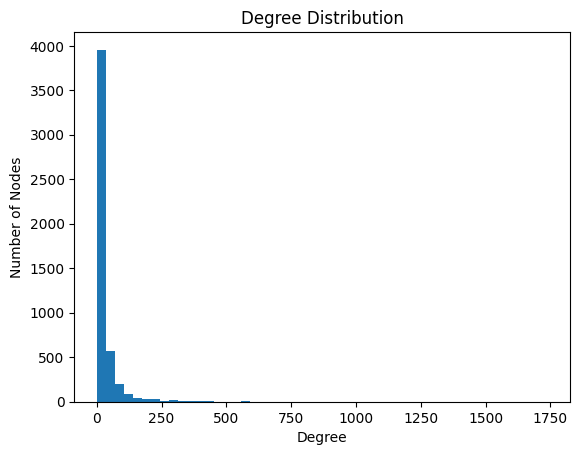

In [1]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

edges = pd.read_csv("reddit_edges_5000.csv")

G = nx.from_pandas_edgelist(
    edges,
    source='Source',
    target='Target',
    create_using=nx.DiGraph()
)

degrees = [d for n, d in G.degree()]

plt.hist(degrees, bins=50)
plt.xlabel("Degree")
plt.ylabel("Number of Nodes")
plt.title("Degree Distribution")
plt.show()

2. In degree & Out degree

In [2]:
indegree = dict(G.in_degree())

outdegree = dict(G.out_degree())

degree_df = pd.DataFrame({
    "Node": list(indegree.keys()),
    "InDegree": indegree.values(),
    "OutDegree": outdegree.values()
})

degree_df.sort_values("InDegree", ascending=False).head(20)

,Node,InDegree,OutDegree
106,askreddit,1425,315
136,iama,1121,320
142,pics,725,3
13,videos,677,2
54,todayilearned,651,0
108,funny,554,37
467,worldnews,536,3
32,gaming,472,172
38,news,465,10
40,outoftheloop,443,426


In [3]:
degree_df.sort_values("OutDegree", ascending=False).head(20)

,Node,InDegree,OutDegree
327,subredditdrama,339,1118
96,copypasta,41,512
763,drama,74,508
40,outoftheloop,443,426
2494,circlejerkcopypasta,15,423
782,shitliberalssay,22,410
2024,justunsubbed,15,395
802,circlebroke,56,372
283,conspiracy,234,360
1492,hailcorporate,51,359


3. Reciprocity

In [4]:
nx.reciprocity(G)

0.23216346980376748

4. Assortativity

In [6]:
nx.degree_assortativity_coefficient(G)

-0.09734675349523539

In [7]:
import pandas as pd

df = pd.read_csv("reddit_features.csv")

df.head()

,Id,Label,indegree,outdegree,Degree,Eccentricity,closnesscentrality,harmonicclosnesscentrality,betweenesscentrality,componentnumber,strongcompnum,modularity_class,clustering,pageranks
0,100daysofketo,NaN,4,5,9,7,0.271097,0.281354,35.881641,0,179,12,0.404762,0.000084
1,bodyweightfitness,NaN,31,32,63,6,0.334641,0.352536,14245.308552,0,179,12,0.113312,0.000376
2,documentaries,NaN,147,7,154,6,0.314649,0.328662,5662.207665,0,179,0,0.098205,0.000979
3,keto,NaN,39,74,113,6,0.349784,0.372378,30989.533149,0,179,12,0.092427,0.000383
4,loseit,NaN,63,71,134,6,0.354193,0.376928,56431.131922,0,179,12,0.105897,0.000645


In [8]:
print(df.columns)

Index(['Id', 'Label', 'indegree', 'outdegree', 'Degree', 'Eccentricity',
       'closnesscentrality', 'harmonicclosnesscentrality',
       'betweenesscentrality', 'componentnumber', 'strongcompnum',
       'modularity_class', 'clustering', 'pageranks'],
      dtype='str')


#### PageRank identifies the most influential communities in the Reddit Hyperlink network.

In [10]:
top_pr = df.sort_values("pageranks", ascending=False)

top_pr[["Id", "pageranks"]].head(10)

,Id,pageranks
136,iama,0.015194
106,askreddit,0.015008
142,pics,0.007794
13,videos,0.007508
54,todayilearned,0.005342
40,outoftheloop,0.005207
32,gaming,0.005057
108,funny,0.004486
467,worldnews,0.004481
38,news,0.004153


#### Degree → Which communities are the most connected?

In [11]:
top_degree = df.sort_values("Degree", ascending=False)

top_degree[["Id", "Degree"]].head(10)

,Id,Degree
106,askreddit,1740
327,subredditdrama,1457
136,iama,1441
40,outoftheloop,869
142,pics,728
13,videos,679
54,todayilearned,651
32,gaming,644
390,legaladvice,606
283,conspiracy,594


#### Betweenness → Which communities act as bridges between different groups?

In [14]:
top_between = df.sort_values("betweenesscentrality", ascending=False)

top_between[["Id", "betweenesscentrality"]].head(10)

,Id,betweenesscentrality
106,askreddit,3.220941e+06
327,subredditdrama,3.030884e+06
136,iama,2.753945e+06
40,outoftheloop,1.613352e+06
390,legaladvice,7.880078e+05
319,writingprompts,6.879071e+05
32,gaming,6.696013e+05
283,conspiracy,6.473758e+05
35,leagueoflegends,5.319821e+05
30,explainlikeimfive,4.852872e+05


#### Closeness → Which communities can quickly reach the rest of the network?

In [16]:
top_close = df.sort_values("closnesscentrality", ascending=False)

top_close[["Id", "closnesscentrality"]].head(10)

,Id,closnesscentrality
4225,programmingprompts,1.0
610,adultdiapers,1.0
4443,gtamodding,1.0
4709,rule34,1.0
2899,coinedup,1.0
4887,supersrp,1.0
4842,propagandamaps,1.0
4583,rarepuppers,1.0
2115,combinedgifs,1.0
4442,gta_5_hack_online,1.0


#### Modularity → Which communities belong to the same interest group?

In [18]:
df["modularity_class"].value_counts()
#community | number of nodes

modularity_class
0     931
16    874
18    697
19    514
3     283
9     212
6     200
15    174
5     149
14    139
12    115
1     115
20    103
7      99
22     61
23     54
4      54
2      50
24     49
8      48
21     36
10     21
13     10
17      7
11      2
Name: count, dtype: int64

#### first 30 subreddits in community 0

In [19]:
df[df["modularity_class"] == 0][["Id"]].head(30)

,Id
2,documentaries
10,movies
24,redditrequest
28,bestof
34,greenlattice
38,news
49,technology
52,the_donald
132,engineering
138,marvelstudios


#### first 30 subreddits in community 16

In [20]:
df[df["modularity_class"] == 16][["Id"]].head(30)


,Id
13,videos
18,youshouldknow
26,4chan
30,explainlikeimfive
32,gaming
39,nostupidquestions
40,outoftheloop
41,placestart
45,riseagainst
47,subredditsimulator


#### first 30 subreddits in community 18

In [21]:
df[df["modularity_class"] == 18][["Id"]].head(30)

,Id
8,gamedetectives
9,megalinks
25,2007scape
33,grandtheftautov
36,masseffect
37,mmorpg
44,puzzleanddragons
46,runescape
48,teamviewer
55,twitch


#### first 30 subreddits in community 19

In [22]:
df[df["modularity_class"] == 19][["Id"]].head(30)

,Id
6,10cloverfieldlane
7,amateurradio
11,newjersey
12,thewalkingdead
111,shittylifeprotips
121,diy
127,beardeddragons
136,iama
139,maya
143,realestatetechnology
